In [ ]:
# 1. Install dependencies if needed (run once)
# %pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn xgboost lightgbm shap

# Telco Customer Churn — Corrected Reimplementation of the Multi-Model Ensemble Paper

Pipeline: preprocessing → feature engineering → stratified split → **SMOTE inside CV (never on validation data)** → tuned XGBoost / LightGBM / Gradient Boosting → **isotonic calibration on real-distribution data** → equal-weight soft voting → **F1 threshold chosen on out-of-fold predictions (not on the test set)** → single final evaluation on the untouched test set.

### What changed compared with the first version
| # | Problem in the original | Fix here |
|---|---|---|
| 1 | SMOTE was applied before `RandomizedSearchCV`, so synthetic neighbours of validation points leaked into training folds (CV F1 ≈ 0.86 vs test F1 ≈ 0.59) | SMOTE is a step of an `imblearn` Pipeline, so it runs only on each training fold; validation folds are real data |
| 2 | Isotonic calibration was fitted on SMOTE-balanced data (50% prior instead of ≈26.5%); Brier got worse for all three models | Calibration is fitted on the real (non-SMOTE) distribution; SMOTE is applied only inside each calibration training fold |
| 3 | The F1-optimal threshold was searched on the test set and reported as the final result | Threshold is selected on out-of-fold predictions from the training set; the test set is used once |
| 4 | `bagging_fraction` had no effect (LightGBM needs `bagging_freq > 0`) | `subsample_freq=1` is fixed so `subsample` is really used |
| 5 | Single split, no uncertainty | Bootstrap 95% CI for the final test F1 |
| 6 | Debug cells, duplicated `"Yes"` in `isin`, `include=["object"]` (fragile with pandas 3) | Cleaned up |

> The paper reports F1 ≈ 0.84. On this dataset that is hard to reconcile with a leak-free evaluation of the *churn* class; a leaky CV score (or a weighted-average F1) can land near that value. Compare your final table against the paper with that in mind.

Requires reasonably recent `scikit-learn`, `imbalanced-learn` (≥ 0.13), `xgboost`, `lightgbm`.

In [1]:
# 2. Imports and reproducibility
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, brier_score_loss
)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# 3. Load the Telco Customer Churn dataset
# Put telco_customer_churn.csv next to this notebook.
DATA_PATH = "telco_customer_churn.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
# 4. Basic cleaning
df = df.copy()

if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

df = df.replace([" ", "?"], np.nan)

# TotalCharges is blank for customers with tenure == 0 (11 rows) -> 0 is the natural value
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
assert df["Churn"].notna().all(), "Unexpected values in Churn column"

print(df.isna().sum().sort_values(ascending=False).head(5))
print("\nChurn distribution:")
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).mul(100).round(2))

gender           0
SeniorCitizen    0
Partner          0
Dependents       0
tenure           0
dtype: int64

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [4]:
# 5. Feature engineering (inspired by the paper)
# AvgMonthlyCharge = TotalCharges / tenure (falls back to MonthlyCharges when tenure == 0)
# HasMultipleServices = more than one subscribed service

df_fe = df.copy()

df_fe["AvgMonthlyCharge"] = (
    df_fe["TotalCharges"] / df_fe["tenure"].replace(0, np.nan)
).fillna(df_fe["MonthlyCharges"])

service_cols = [c for c in [
    "PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
] if c in df_fe.columns]

n_services = sum((df_fe[c] == "Yes").astype(int) for c in service_cols)
df_fe["HasMultipleServices"] = (n_services > 1).astype(int)

display(df_fe[["AvgMonthlyCharge", "HasMultipleServices"]].head())

,AvgMonthlyCharge,HasMultipleServices
0,29.850000,0
1,55.573529,1
2,54.075000,1
3,40.905556,1
4,75.825000,0


In [5]:
# 6. Stratified train/test split (the test set is touched only once, at the end)
X = df_fe.drop(columns=["Churn"])
y = df_fe["Churn"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), "| Test churn rate:", round(y_test.mean(), 4))

Train: (5634, 21) | Test: (1409, 21)
Train churn rate: 0.2654 | Test churn rate: 0.2654


In [6]:
# 7. One-hot encoding (fitted on train only)
# The encoder is unsupervised and deterministic, so fitting it once on the training set
# introduces no label leakage into cross-validation.
# NOTE: SMOTE is NOT applied here. It lives inside the model pipelines (cell 9).

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
        ("num", "passthrough", numeric_cols),
    ],
    remainder="drop",
)

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_enc = pd.DataFrame(X_train_enc, columns=feature_names, index=X_train.index)
X_test_enc = pd.DataFrame(X_test_enc, columns=feature_names, index=X_test.index)

print("Encoded train shape:", X_train_enc.shape)

Encoded train shape: (5634, 47)


In [7]:
# 8. Cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# A different split is used later for out-of-fold predictions (calibration + threshold)
cv_oof = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)

In [8]:
# 9. Hyperparameter tuning — SMOTE is applied ONLY to the training part of each fold

def make_pipe(clf):
    return ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", clf),
    ])

def tune(name, clf, param_dist, n_iter=30):
    search = RandomizedSearchCV(
        estimator=make_pipe(clf),
        param_distributions={f"clf__{k}": v for k, v in param_dist.items()},
        n_iter=n_iter,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
        refit=True,
    )
    search.fit(X_train_enc, y_train)          # raw (non-SMOTE) training data
    print(f"\n{name}: best CV F1 on real validation folds = {search.best_score_:.4f}")
    print({k.replace("clf__", ""): v for k, v in search.best_params_.items()})
    return search

# --- XGBoost ---
xgb = XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                    random_state=RANDOM_STATE, n_jobs=1)
xgb_param_dist = {
    "learning_rate": np.linspace(0.01, 0.10, 10),
    "max_depth": list(range(3, 9)),
    "n_estimators": list(range(300, 701, 50)),
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.2],
}
xgb_search = tune("XGBoost", xgb, xgb_param_dist)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

XGBoost: best CV F1 on real validation folds = 0.6231
{'subsample': 0.7, 'n_estimators': 550, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': np.float64(0.01), 'gamma': 0.1, 'colsample_bytree': 1.0}


In [9]:
# 10. LightGBM
# subsample_freq=1 is fixed: without it LightGBM ignores `subsample` (bagging_fraction) entirely.
lgbm = LGBMClassifier(objective="binary", subsample_freq=1,
                      random_state=RANDOM_STATE, verbosity=-1, n_jobs=1)
lgbm_param_dist = {
    "num_leaves": list(range(20, 101, 10)),
    "learning_rate": np.linspace(0.01, 0.08, 8),
    "n_estimators": list(range(300, 701, 50)),
    "colsample_bytree": [0.70, 0.75, 0.80, 0.85, 0.90, 0.95],   # = feature_fraction
    "subsample": [0.70, 0.75, 0.80, 0.85, 0.90, 0.95],          # = bagging_fraction
    "min_child_samples": list(range(20, 121, 10)),              # = min_data_in_leaf
}
lgbm_search = tune("LightGBM", lgbm, lgbm_param_dist)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

LightGBM: best CV F1 on real validation folds = 0.6000
{'subsample': 0.7, 'num_leaves': 50, 'n_estimators': 300, 'min_child_samples': 60, 'learning_rate': np.float64(0.01), 'colsample_bytree': 0.8}


In [10]:
# 11. Gradient Boosting
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_param_dist = {
    "n_estimators": list(range(100, 601, 50)),
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.07, 0.10],
    "max_depth": [2, 3, 4, 5],
    "min_samples_leaf": [1, 2, 5, 10],
    "subsample": [0.7, 0.8, 0.9, 1.0],
}
gb_search = tune("Gradient Boosting", gb, gb_param_dist)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

Gradient Boosting: best CV F1 on real validation folds = 0.6303
{'subsample': 1.0, 'n_estimators': 150, 'min_samples_leaf': 5, 'max_depth': 3, 'learning_rate': 0.02}


In [11]:
# 12. Helper functions

def metrics_row(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "Model": name,
        "Threshold": round(float(threshold), 3),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1 (churn)": f1_score(y_true, pred, zero_division=0),
        "F1 (weighted)": f1_score(y_true, pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

def find_best_threshold(y_true, prob, grid=np.arange(0.10, 0.701, 0.005), smooth=5):
    # F1 vs threshold is noisy; a small moving average avoids picking a lucky spike.
    f1s = np.array([f1_score(y_true, (prob >= t).astype(int), zero_division=0) for t in grid])
    f1s_smooth = np.convolve(f1s, np.ones(smooth) / smooth, mode="same")
    return float(grid[f1s_smooth.argmax()]), grid, f1s

best_pipes = {
    "XGBoost": xgb_search.best_estimator_,
    "LightGBM": lgbm_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_,
}

# Uncalibrated test probabilities (reference only; nothing is selected from them)
p_test_uncal = {n: p.predict_proba(X_test_enc)[:, 1] for n, p in best_pipes.items()}

In [12]:
# 13. Isotonic calibration on the REAL distribution
# CalibratedClassifierCV is given the raw (non-SMOTE) training data. For each of its 5 folds the
# pipeline applies SMOTE only to the fold's training part, and the isotonic calibrator is fitted
# on the untouched validation part, i.e. on real class proportions.

cal_models = {}
for name, pipe in best_pipes.items():
    cal = CalibratedClassifierCV(estimator=pipe, method="isotonic", cv=cv)
    cal.fit(X_train_enc, y_train)
    cal_models[name] = cal
    print("Calibrated:", name)

p_test_cal = {n: m.predict_proba(X_test_enc)[:, 1] for n, m in cal_models.items()}

Calibrated: XGBoost
Calibrated: LightGBM
Calibrated: Gradient Boosting


In [13]:
# 14. Out-of-fold predictions on the training set (for threshold selection)
# Each OOF prediction comes from a model that never saw that row (including its calibration).
# This is the slowest cell: 3 models x 5 outer folds x (5 inner calibration fits).

oof_probs = {}
for name, cal in cal_models.items():
    oof_probs[name] = cross_val_predict(
        clone(cal), X_train_enc, y_train,
        cv=cv_oof, method="predict_proba", n_jobs=-1
    )[:, 1]
    print("OOF done:", name)

p_oof_ens = np.mean([oof_probs[n] for n in cal_models], axis=0)

OOF done: XGBoost
OOF done: LightGBM
OOF done: Gradient Boosting


Threshold selected on OOF predictions: 0.340
OOF F1 at that threshold (train): 0.6416


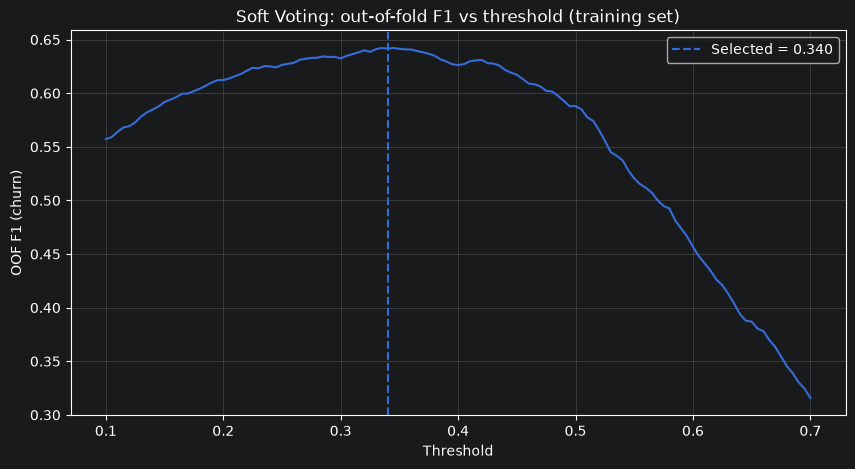

In [14]:
# 15. Soft voting (equal weights) + threshold chosen on OOF predictions only
p_test_ens = np.mean([p_test_cal[n] for n in cal_models], axis=0)

best_threshold, grid, oof_f1_curve = find_best_threshold(y_train, p_oof_ens)
oof_f1_at_best = f1_score(y_train, (p_oof_ens >= best_threshold).astype(int))

print(f"Threshold selected on OOF predictions: {best_threshold:.3f}")
print(f"OOF F1 at that threshold (train): {oof_f1_at_best:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(grid, oof_f1_curve)
plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.3f}")
plt.xlabel("Threshold"); plt.ylabel("OOF F1 (churn)")
plt.title("Soft Voting: out-of-fold F1 vs threshold (training set)")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

              precision    recall  f1-score   support

    No Churn     0.8909    0.7894    0.8371      1035
       Churn     0.5569    0.7326    0.6328       374

    accuracy                         0.7743      1409
   macro avg     0.7239    0.7610    0.7349      1409
weighted avg     0.8023    0.7743    0.7829      1409

Final Ensemble F1 (churn): 0.6328
Final Ensemble ROC-AUC   : 0.8437
Bootstrap 95% CI for test F1: [0.592, 0.670]


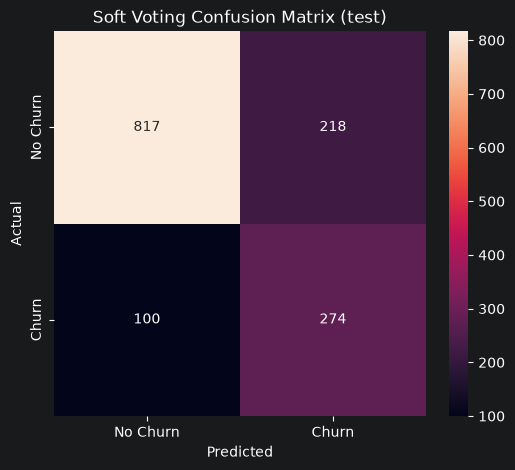

In [15]:
# 16. FINAL evaluation on the untouched test set (threshold fixed beforehand)
final_pred = (p_test_ens >= best_threshold).astype(int)

print(classification_report(y_test, final_pred, target_names=["No Churn", "Churn"], digits=4))
print("Final Ensemble F1 (churn):", round(f1_score(y_test, final_pred), 4))
print("Final Ensemble ROC-AUC   :", round(roc_auc_score(y_test, p_test_ens), 4))

# Bootstrap 95% CI for test F1 (the test set has only ~1.4k rows)
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append(f1_score(y_arr[idx], final_pred[idx], zero_division=0))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Bootstrap 95% CI for test F1: [{lo:.3f}, {hi:.3f}]")

cm = confusion_matrix(y_test, final_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Soft Voting Confusion Matrix (test)")
plt.show()

In [16]:
# 17. Final comparison table (all on the same untouched test set)
rows = []
for n in cal_models:
    rows.append(metrics_row(f"{n} (uncalibrated, 0.5)", y_test, p_test_uncal[n], 0.5))
for n in cal_models:
    rows.append(metrics_row(f"{n} (calibrated, 0.5)", y_test, p_test_cal[n], 0.5))
for n in cal_models:
    t_n, _, _ = find_best_threshold(y_train, oof_probs[n])     # per-model OOF threshold
    rows.append(metrics_row(f"{n} (calibrated, OOF threshold)", y_test, p_test_cal[n], t_n))
rows.append(metrics_row("Soft Voting (0.5)", y_test, p_test_ens, 0.5))
rows.append(metrics_row("Soft Voting (OOF threshold)", y_test, p_test_ens, best_threshold))

final_results = pd.DataFrame(rows)
display(final_results.sort_values("F1 (churn)", ascending=False).round(4).reset_index(drop=True))

# Did calibration help? Compare Brier score (lower is better)
display(pd.DataFrame({
    "Brier uncalibrated": {n: brier_score_loss(y_test, p_test_uncal[n]) for n in cal_models},
    "Brier calibrated":   {n: brier_score_loss(y_test, p_test_cal[n])   for n in cal_models},
}).round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1 (churn),F1 (weighted),ROC-AUC,Brier
0,Soft Voting (OOF threshold),0.34,0.7743,0.5569,0.7326,0.6328,0.7829,0.8437,0.1366
1,"LightGBM (calibrated, OOF threshold)",0.32,0.7630,0.5376,0.7647,0.6313,0.7738,0.8433,0.1365
2,"XGBoost (calibrated, OOF threshold)",0.34,0.7736,0.5562,0.7273,0.6304,0.7820,0.8443,0.1364
3,"Gradient Boosting (calibrated, OOF threshold)",0.34,0.7729,0.5553,0.7246,0.6288,0.7813,0.8386,0.1394
4,"Gradient Boosting (uncalibrated, 0.5)",0.50,0.7779,0.5692,0.6711,0.6160,0.7833,0.8388,0.1459
5,"XGBoost (uncalibrated, 0.5)",0.50,0.7842,0.5858,0.6390,0.6113,0.7871,0.8450,0.1392
6,"LightGBM (calibrated, 0.5)",0.50,0.8006,0.6545,0.5267,0.5837,0.7932,0.8433,0.1365
7,"XGBoost (calibrated, 0.5)",0.50,0.7991,0.6492,0.5294,0.5832,0.7922,0.8443,0.1364
8,"Gradient Boosting (calibrated, 0.5)",0.50,0.7999,0.6523,0.5267,0.5828,0.7926,0.8386,0.1394
9,Soft Voting (0.5),0.50,0.7984,0.6500,0.5214,0.5786,0.7909,0.8437,0.1366


,Brier uncalibrated,Brier calibrated
XGBoost,0.1392,0.1364
LightGBM,0.1385,0.1365
Gradient Boosting,0.1459,0.1394


## Optional: SHAP explainability
SHAP is computed for the XGBoost model of the tuned pipeline (trained on the SMOTE-resampled full training set). It explains that single model, not the calibrated ensemble.

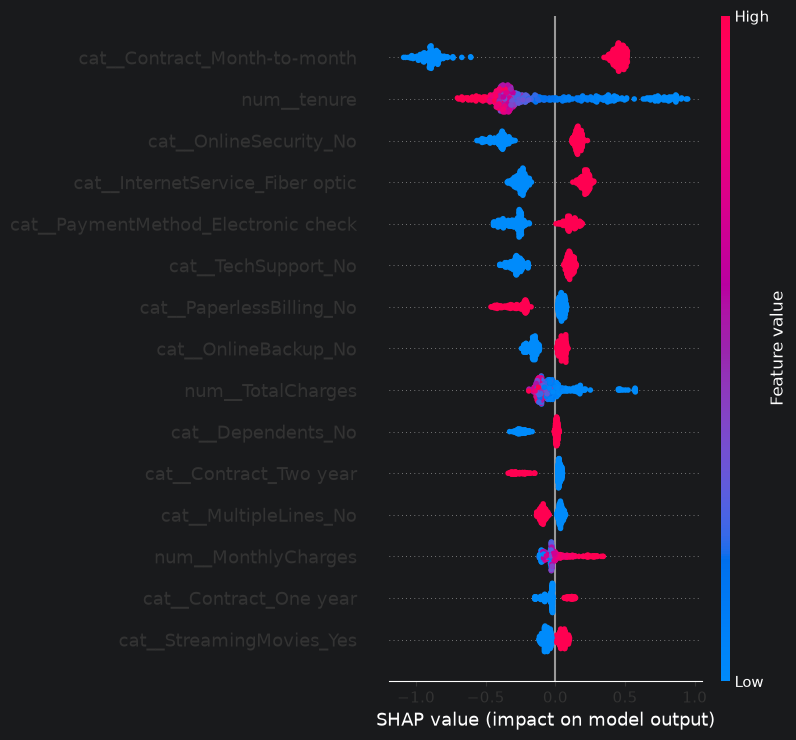

In [17]:
# 18. SHAP — optional
try:
    import shap

    xgb_model = xgb_search.best_estimator_.named_steps["clf"]
    X_shap = X_test_enc.sample(n=min(500, len(X_test_enc)), random_state=RANDOM_STATE)

    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_shap)
    shap.summary_plot(shap_values, X_shap, max_display=15)

except ImportError:
    print("Install SHAP first with: %pip install shap")

## Paper benchmark (for reference)

| Model | F1 reported in paper |
|---|---:|
| Random Forest | 0.81 |
| XGBoost | 0.84 |
| LightGBM | 0.84 |
| Gradient Boosting | 0.84 |
| AdaBoost | 0.79 |
| Logistic Regression | 0.78 |
| MLP | 0.76 |
| Soft Voting | 0.84 |

These are the paper's numbers. Compare them with the **`F1 (churn)`** and **`F1 (weighted)`** columns of the final table separately: on this dataset a leak-free churn-class F1 is typically far below 0.84, whereas the weighted F1 is closer to the paper's scale. Whether the paper's value is a weighted average, a leaky CV score, or something else cannot be determined from the notebook alone.

In [18]:
# 19. FINAL MODEL: choose threshold, refit on ALL data, save, and predict on new customers
import joblib

# ---------------- Settings ----------------
FINAL_MODEL = "ensemble"          # "ensemble" or one of: "XGBoost", "LightGBM", "Gradient Boosting"
USE_COST_BASED_THRESHOLD = False  # False -> maximize F1 on OOF | True -> minimize business cost on OOF
COST_FN = 5.0                     # cost of missing a churner (lost customer value)
COST_FP = 1.0                     # cost of a wasted retention offer to a non-churner
# ------------------------------------------

model_names = list(cal_models) if FINAL_MODEL == "ensemble" else [FINAL_MODEL]

# --- 1) Threshold from out-of-fold predictions on the TRAIN set (test set is not used) ---
p_oof_final = np.mean([oof_probs[n] for n in model_names], axis=0)

if USE_COST_BASED_THRESHOLD:
    grid = np.arange(0.05, 0.951, 0.005)
    y_tr = y_train.to_numpy()
    costs = []
    for t in grid:
        pred = (p_oof_final >= t).astype(int)
        fn = ((pred == 0) & (y_tr == 1)).sum()
        fp = ((pred == 1) & (y_tr == 0)).sum()
        costs.append((COST_FN * fn + COST_FP * fp) / len(y_tr))
    costs = np.array(costs)
    costs_smooth = np.convolve(costs, np.ones(5) / 5, mode="same")
    final_threshold = float(grid[costs_smooth[2:-2].argmin() + 2])   # ignore edge effects of smoothing
    print(f"Cost-based threshold: {final_threshold:.3f}  (avg cost per customer: {costs[grid.searchsorted(final_threshold)]:.4f})")
else:
    final_threshold, _, _ = find_best_threshold(y_train, p_oof_final)
    print(f"F1-based threshold: {final_threshold:.3f}")

# Informational: how this threshold behaves on the (already seen) test set
p_test_final = np.mean([p_test_cal[n] for n in model_names], axis=0)
display(pd.DataFrame([metrics_row(f"{FINAL_MODEL} @ {final_threshold:.3f}", y_test, p_test_final, final_threshold)]).round(4))

# --- 2) Refit preprocessing + calibrated models on ALL data (train + test), same hyperparameters ---
full_prep = clone(preprocessor).fit(X)
X_full_enc = pd.DataFrame(full_prep.transform(X),
                          columns=full_prep.get_feature_names_out(), index=X.index)

final_models = {}
for n in model_names:
    m = CalibratedClassifierCV(estimator=clone(best_pipes[n]), method="isotonic", cv=cv)
    m.fit(X_full_enc, y)          # SMOTE runs only inside each training fold
    final_models[n] = m
    print("Refit on full data:", n)

# --- 3) Save everything needed for inference ---
feature_columns = list(X.columns)
bundle = {
    "preprocessor": full_prep,
    "models": final_models,
    "model_names": model_names,
    "threshold": final_threshold,
    "feature_columns": feature_columns,
    "service_cols": service_cols,
}
joblib.dump(bundle, "churn_final_model.joblib")
print("Saved: churn_final_model.joblib")

# --- 4) Prediction function for NEW customers (raw rows, same columns as the original CSV) ---
def prepare_raw(df_raw, service_cols=service_cols, feature_columns=feature_columns):
    d = df_raw.copy()
    d = d.drop(columns=[c for c in ["customerID", "Churn"] if c in d.columns])
    d = d.replace([" ", "?"], np.nan)
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(0)
    d["AvgMonthlyCharge"] = (d["TotalCharges"] / d["tenure"].replace(0, np.nan)).fillna(d["MonthlyCharges"])
    n_services = sum((d[c] == "Yes").astype(int) for c in service_cols)
    d["HasMultipleServices"] = (n_services > 1).astype(int)
    return d[feature_columns]

def predict_churn(df_raw, bundle=bundle):
    d = prepare_raw(df_raw, bundle["service_cols"], bundle["feature_columns"])
    Xe = pd.DataFrame(bundle["preprocessor"].transform(d),
                      columns=bundle["preprocessor"].get_feature_names_out(), index=d.index)
    prob = np.mean([m.predict_proba(Xe)[:, 1] for m in bundle["models"].values()], axis=0)
    return pd.DataFrame({
        "churn_probability": prob.round(4),
        "churn_flag": (prob >= bundle["threshold"]).astype(int),
    }, index=df_raw.index)

# Quick demo on a few rows
display(predict_churn(pd.read_csv(DATA_PATH).head(5)))


F1-based threshold: 0.340


,Model,Threshold,Accuracy,Precision,Recall,F1 (churn),F1 (weighted),ROC-AUC,Brier
0,ensemble @ 0.340,0.34,0.7743,0.5569,0.7326,0.6328,0.7829,0.8437,0.1366


Refit on full data: XGBoost
Refit on full data: LightGBM
Refit on full data: Gradient Boosting
Saved: churn_final_model.joblib


,churn_probability,churn_flag
0,0.5862,1
1,0.0349,0
2,0.3557,1
3,0.0335,0
4,0.7355,1
